# Flows (appendix)

Who is recommended, by prompt variable or model characteristic. Inputs: `metrics/<variant>/flows/` (run_metrics_pipeline.sh -s flows). Plots: `plots/flows_*`.

In [1]:
# Setup: code/libs importable, library changes re-imported automatically
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'code' / 'libs').exists())
sys.path.insert(0, str(PROJECT / 'code' / 'libs'))

from metrics import flows
from utils import analysis_config
from utils import constants as cons
from viz import constants as viscons
from viz import flow_plots
from viz.figures import save_figure
from viz.style import apply_style

apply_style()

'DejaVu Serif'

In [2]:
# Parameters
SMOKE = True                                   # True: smoke-test outputs in tmp/smoke/, False: results/
VARIANT = 'main'                               # metrics/<VARIANT>
SAVE = False
FORMATS = ['png']                              # e.g. ['png', 'pdf']
INCLUDE_UNKNOWN = None                         # None: as the config (social.include_unknown) | True | False
NCOLS = viscons.FLOW_GRID_NCOLS                # panels per row: 3 (2 x 3) | 6 (1 x 6)
TARGETS = flows.TARGETS                        # person attributes: gender, ethnicity, country, author_seniority, productivity, influence
SOURCES = viscons.FLOW_SOURCES                 # prompt variables / model characteristics (target-fixed figures)
RESULTS_DIR = PROJECT / 'tmp' / 'smoke' if SMOKE else Path(cons.DEFAULT_RESULTS_DIR)
METRICS_DIR = RESULTS_DIR / 'metrics' / VARIANT
PLOTS_DIR = RESULTS_DIR / 'plots'
CONFIG = PROJECT / 'config' / ('analysis_smoke.yaml' if SMOKE else 'analysis.yaml')
analysis_config.require_late_reviewed(CONFIG)  # gender labels, valid tags: reviewed (late settings)
config = analysis_config.load(CONFIG)
GENDER_LABELS, BIN_LABELS = config['gender']['labels'], config['prominence']['bin_labels']
INCLUDE_UNKNOWN = config['social']['include_unknown'] if INCLUDE_UNKNOWN is None else INCLUDE_UNKNOWN

In [3]:
# Data: one row per (valid response, factual person) = a MENTION (n in the plots counts mentions: a person recommended
# in several responses counts each time); with the prompt variables, model characteristics and GT attributes
people = flow_plots.with_model_columns(flows.load_people(METRICS_DIR))
print(f"{len(people):,} rows | {people['author_id'].nunique():,} people | {people[cons.COL_MODEL].nunique()} models | unknown: "
      + ', '.join(f"{t} {flows.unknown_share(people, t):.1%}" for t in ['gender', 'ethnicity', 'country']))

1,135 rows | 179 people | 3 models | unknown: gender 3.9%, ethnicity 8.8%, country 16.7%


## Drift: prompted location → country of the recommended people

In [4]:
# Share from the prompt's country vs the same share when other locations are prompted (lift = ratio); 95% CI over models
drift = flows.drift(people)
drift.round(3)

,location,country,n,share,baseline,lift,share_ci_low,share_ci_high,baseline_ci_low,baseline_ci_high,lift_ci_low,lift_ci_high,n_models
0,Canada,CA,241,0.008,0.003,2.921,0.000,0.034,0.000,0.005,0.000,6.621,3
1,Ecuador,EC,345,0.003,0.005,0.580,0.000,0.005,0.000,0.010,0.405,0.904,3
2,Germany,DE,121,0.397,0.056,7.106,0.161,0.581,0.047,0.068,2.355,12.484,3
3,Japan,JP,134,0.299,0.000,NaN,0.091,0.923,0.000,0.000,NaN,NaN,3
4,South Africa,ZA,104,0.000,0.000,NaN,0.000,0.000,0.000,0.000,NaN,NaN,3


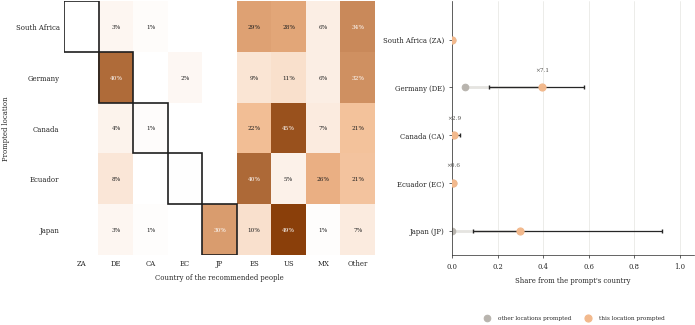

In [5]:
# Heatmap of the country shares per prompted location (own country outlined) and the drift per location
fig = flow_plots.plot_drift(people, drift)
if SAVE:
    save_figure(fig, 'flows_drift_location', PLOTS_DIR, FORMATS)

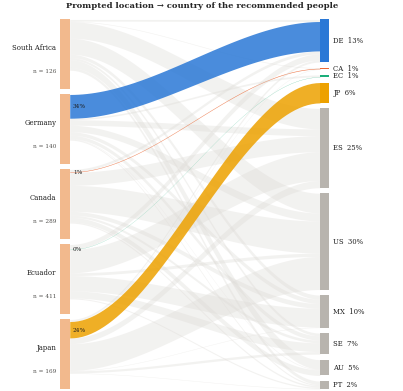

In [6]:
# The drift as a flow: each location's band to its own country in colour, the others faded
fig = flow_plots.plot_drift_flow(people, include_unknown=INCLUDE_UNKNOWN)
if SAVE:
    save_figure(fig, 'flows_drift_location_flow', PLOTS_DIR, FORMATS)

## Flows: one prompt variable → the people's attributes

Bands: within-value shares; right: mean composition. Factual people = matched at the author level (name + requested field + seniority), so their seniority mostly follows the requested one.

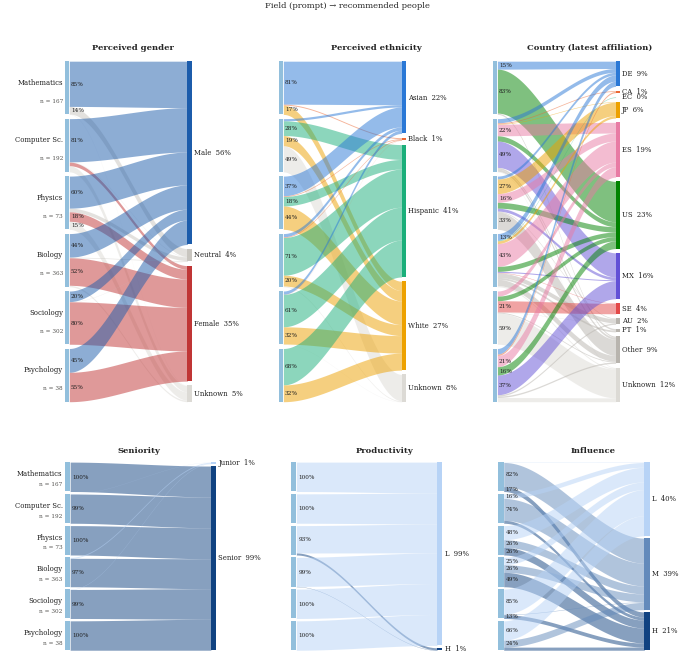

In [7]:
fig = flow_plots.plot_flow_grid(people, source='field', targets=TARGETS, ncols=NCOLS, include_unknown=INCLUDE_UNKNOWN,
                                     gender_labels=GENDER_LABELS, bin_labels=BIN_LABELS)
if SAVE:
    save_figure(fig, 'flows_field', PLOTS_DIR, FORMATS)

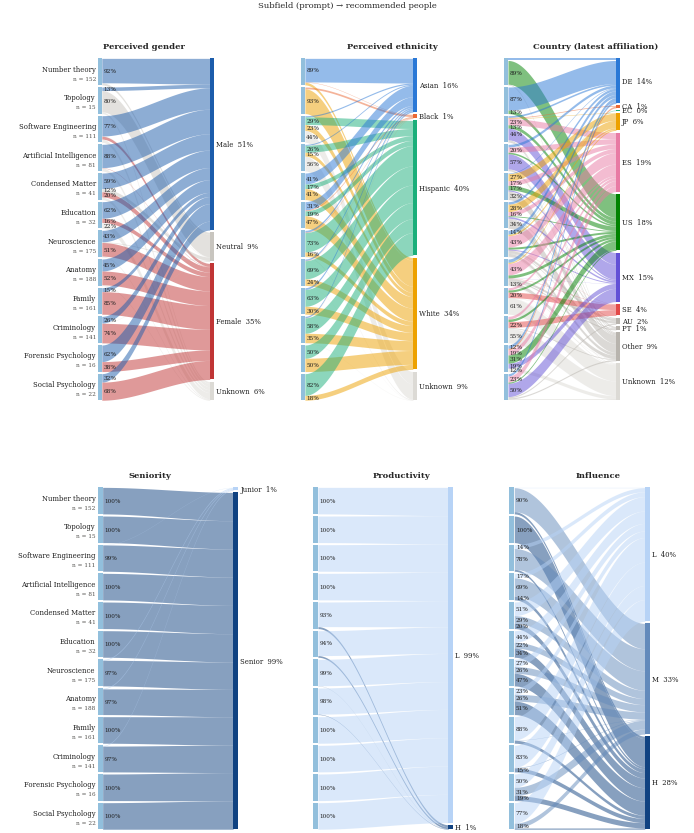

In [8]:
fig = flow_plots.plot_flow_grid(people, source='subfield', targets=TARGETS, ncols=NCOLS, include_unknown=INCLUDE_UNKNOWN,
                                     gender_labels=GENDER_LABELS, bin_labels=BIN_LABELS)
if SAVE:
    save_figure(fig, 'flows_subfield', PLOTS_DIR, FORMATS)

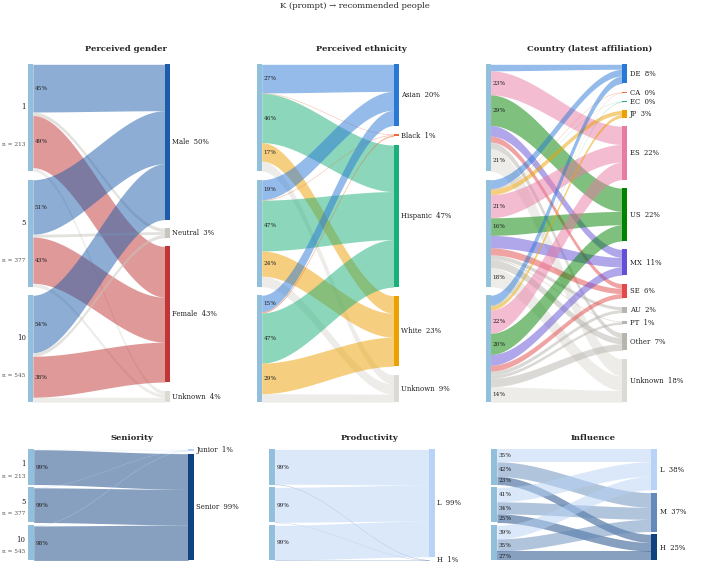

In [9]:
fig = flow_plots.plot_flow_grid(people, source='k', targets=TARGETS, ncols=NCOLS, include_unknown=INCLUDE_UNKNOWN,
                                     gender_labels=GENDER_LABELS, bin_labels=BIN_LABELS)
if SAVE:
    save_figure(fig, 'flows_k', PLOTS_DIR, FORMATS)

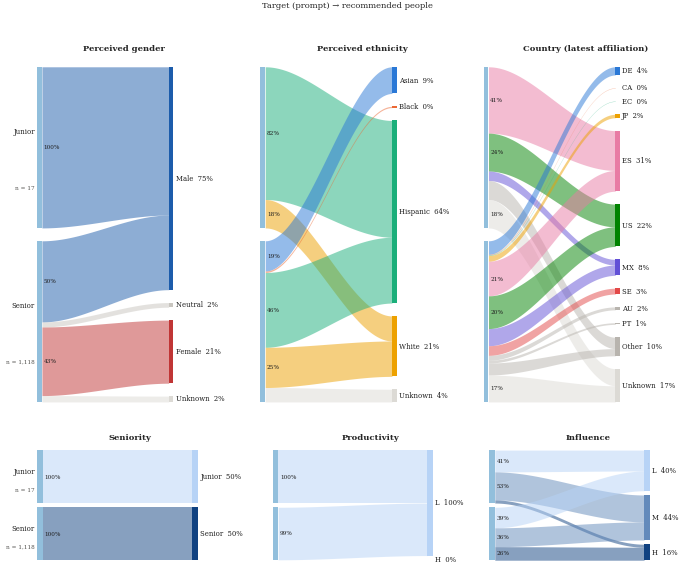

In [10]:
fig = flow_plots.plot_flow_grid(people, source='seniority', targets=TARGETS, ncols=NCOLS, include_unknown=INCLUDE_UNKNOWN,
                                     gender_labels=GENDER_LABELS, bin_labels=BIN_LABELS)
if SAVE:
    save_figure(fig, 'flows_seniority', PLOTS_DIR, FORMATS)

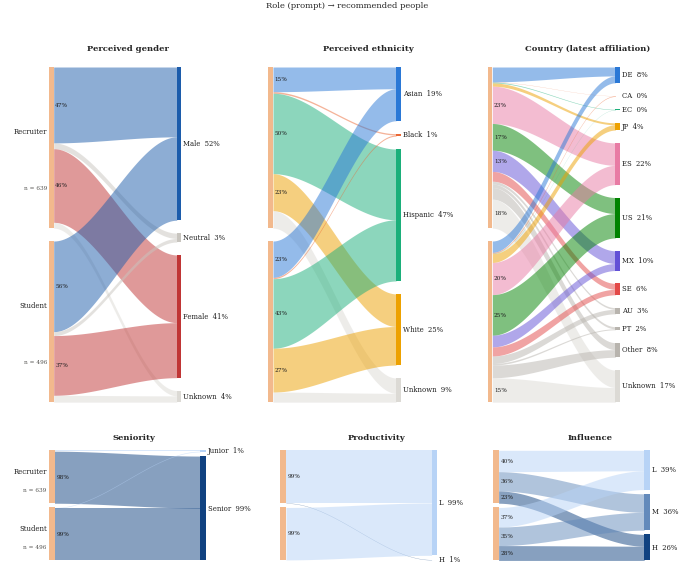

In [11]:
fig = flow_plots.plot_flow_grid(people, source='role', targets=TARGETS, ncols=NCOLS, include_unknown=INCLUDE_UNKNOWN,
                                     gender_labels=GENDER_LABELS, bin_labels=BIN_LABELS)
if SAVE:
    save_figure(fig, 'flows_role', PLOTS_DIR, FORMATS)

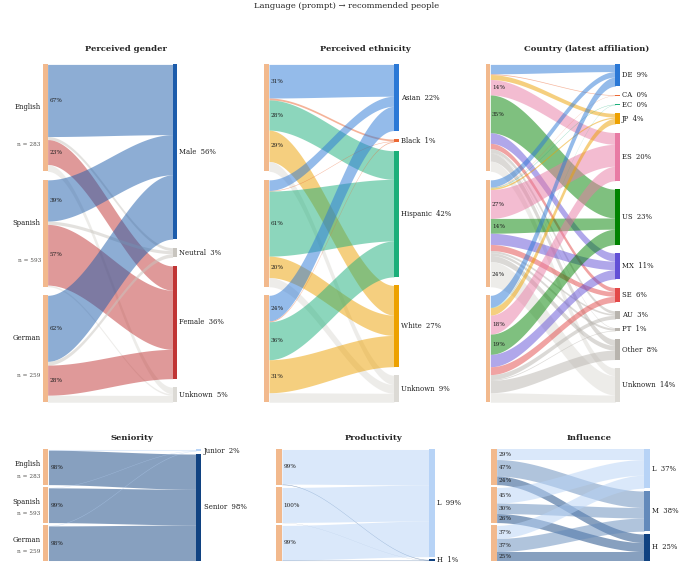

In [12]:
fig = flow_plots.plot_flow_grid(people, source='language', targets=TARGETS, ncols=NCOLS, include_unknown=INCLUDE_UNKNOWN,
                                     gender_labels=GENDER_LABELS, bin_labels=BIN_LABELS)
if SAVE:
    save_figure(fig, 'flows_language', PLOTS_DIR, FORMATS)

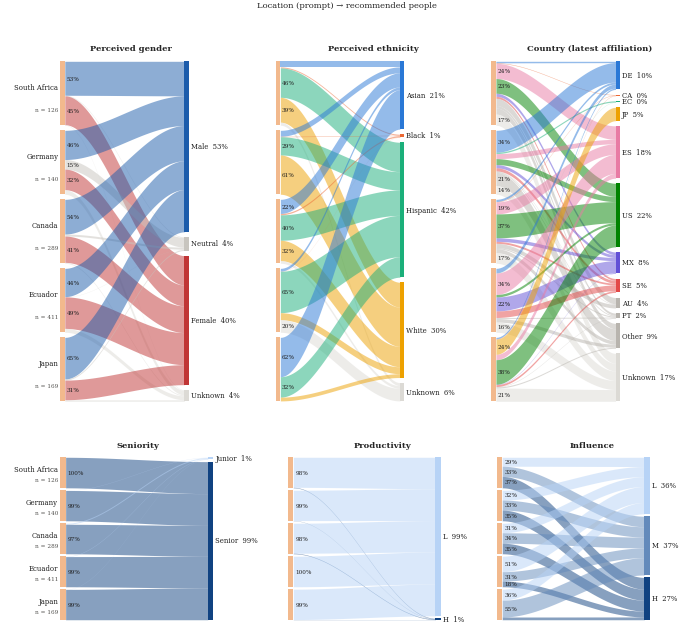

In [13]:
fig = flow_plots.plot_flow_grid(people, source='location', targets=TARGETS, ncols=NCOLS, include_unknown=INCLUDE_UNKNOWN,
                                     gender_labels=GENDER_LABELS, bin_labels=BIN_LABELS)
if SAVE:
    save_figure(fig, 'flows_location', PLOTS_DIR, FORMATS)

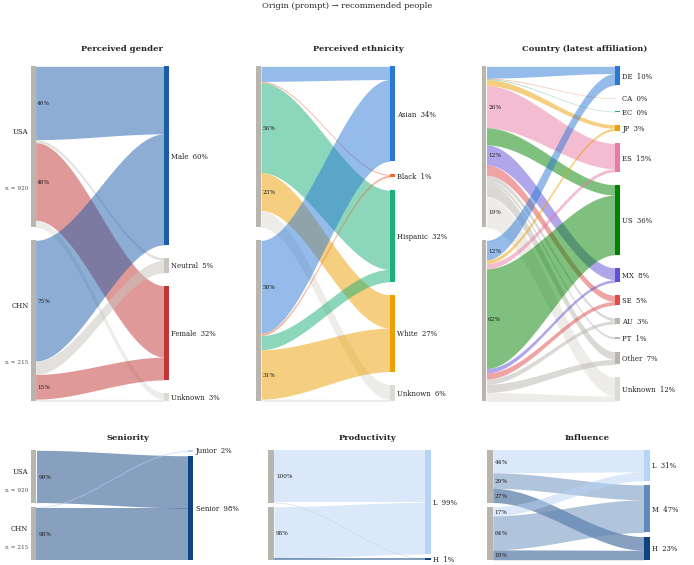

In [14]:
fig = flow_plots.plot_flow_grid(people, source='origin', targets=TARGETS, ncols=NCOLS, include_unknown=INCLUDE_UNKNOWN,
                                     gender_labels=GENDER_LABELS, bin_labels=BIN_LABELS)
if SAVE:
    save_figure(fig, 'flows_origin', PLOTS_DIR, FORMATS)

## Flows: prompt variables → one attribute of the people

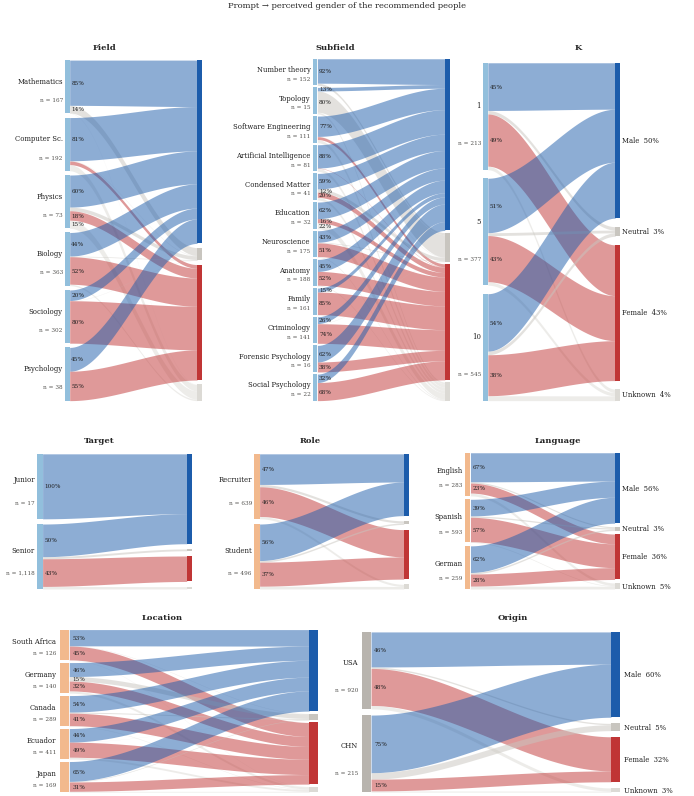

In [15]:
fig = flow_plots.plot_flow_grid(people, target='gender', sources=SOURCES, ncols=NCOLS, include_unknown=INCLUDE_UNKNOWN,
                                gender_labels=GENDER_LABELS, bin_labels=BIN_LABELS)
if SAVE:
    save_figure(fig, 'flows_to_gender', PLOTS_DIR, FORMATS)

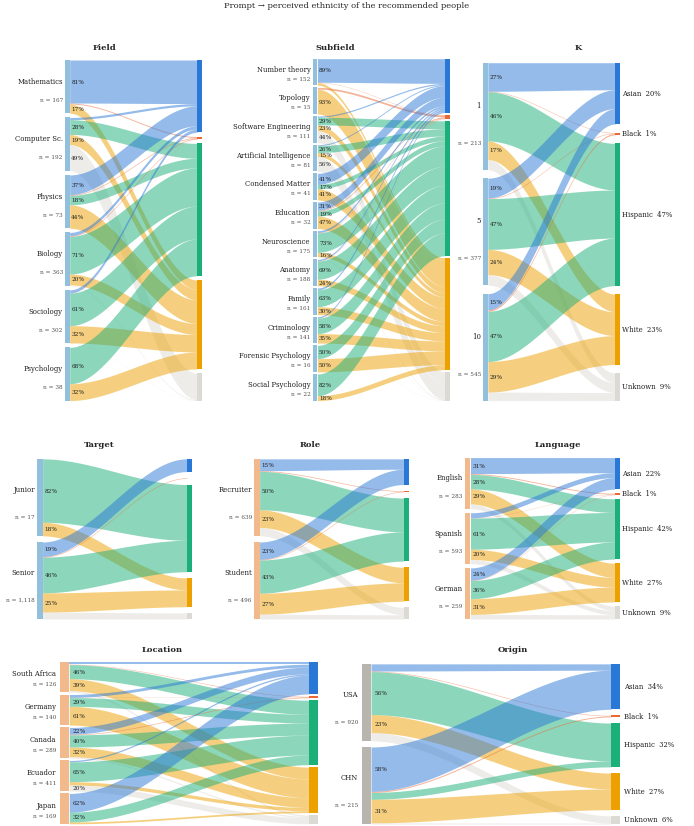

In [16]:
fig = flow_plots.plot_flow_grid(people, target='ethnicity', sources=SOURCES, ncols=NCOLS, include_unknown=INCLUDE_UNKNOWN,
                                gender_labels=GENDER_LABELS, bin_labels=BIN_LABELS)
if SAVE:
    save_figure(fig, 'flows_to_ethnicity', PLOTS_DIR, FORMATS)

## Any other flow

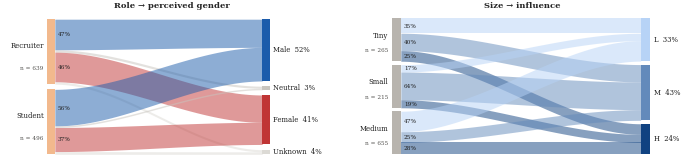

In [17]:
# Sources: prompt variables (language, role, location, k, seniority, field, subfield) or model characteristics
# (access, size, reasoning, origin, family); targets: gender, ethnicity, country, productivity, influence, collaboration
PAIRS = [('role', 'gender'), ('size', 'influence')]
fig = flow_plots.plot_flows(people, PAIRS, INCLUDE_UNKNOWN, GENDER_LABELS, BIN_LABELS)

In [18]:
# Table: shares of the target classes per source value
flows.flow_table(people, 'origin', 'country', INCLUDE_UNKNOWN, top=viscons.FLOW_TOP_COUNTRIES) \
     .pivot(index='source', columns='target', values='share').round(3)

target,AU,DE,ES,JP,MX,PT,SE,US,other,unknown
source,,,,,,,,,,
CHN,0.033,0.121,0.033,0.023,0.028,NaN,0.037,0.619,0.051,0.056
USA,0.029,0.074,0.261,0.038,0.124,0.021,0.064,0.107,0.089,0.193
